In [ ]:
#%%
import math
import numpy as np
import inspect
import importlib

import scipy.interpolate

import matplotlib
from matplotlib import pyplot as plt
import matplotlib.pyplot as plt

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = 16

import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
from plotly.offline import plot
pio.renderers.default = "svg"

import sys
import os
parent_directory = os.path.dirname(os.getcwd())
sys.path.append(parent_directory)
#parent_directory = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
#sys.path.append(parent_directory)
 
import IoT_node_models 
from IoT_node_models import *

path_to_save_svg = "Saved_Data"



In [ ]:
fontsize        = 14
fontsize_perc   = 12
fontsize_ytick  = 12
fontsize_legend = 8

matplotlib.rcParams.update({'font.size': fontsize})
matplotlib.rcParams['lines.linewidth']      = 1.5
matplotlib.rcParams['xtick.major.size']     = 5
matplotlib.rcParams['xtick.major.width']    = 1
matplotlib.rcParams['ytick.major.size']     = 5
matplotlib.rcParams['ytick.major.width']    = 1
matplotlib.rc('axes', linewidth=1)


matplotlib.rcParams["font.family"] =  'Avenir LT Pro'
matplotlib.rcParams['figure.facecolor'] = 'white'
matplotlib.rcParams['svg.fonttype'] = 'none'

In [ ]:

#importlib.reload(IoT_node_models)
#from IoT_node_models import *

In [ ]:
Node_supply = 3.3

In [ ]:
this_hw = Hardware(name= "IoT Node",footprintStructure=None, categories=DEFAULT_CATEGORIES)
for comp in component_List:
    comp.set_factors(None)
    comp.set_v(Node_supply)
    this_hw.add(comp)
    

In [ ]:

this_LDO = LDO(name = "Node LDO", category = "Power_supply", v_out = Node_supply, i_q = 1e-3, v_in = Node_supply, component_list = component_List)     # XC6206 : 0.228 + Diode and Transistor?
this_Batt= Battery(name = "Node Batt.", category = "Battery", v = Node_supply, capacity_mAh = 2800, i = 0, selfdischarge_p_year = 5)
this_hw.add(this_LDO)
this_hw.add(this_Batt)


In [ ]:

this_profile= LoRa_Profile("Profile", this_hw,  RX_state=radio_state_RX,TX_state=radio_state_TX,
                    P_TX= PTX_PABOOST[Node_supply], I_TX=I_PABoost[Node_supply] ) 
             

In [ ]:

this_task_tx0 = this_profile.create_task_tx(name="TX-0", Ptx = 17,SF=7 ,Coding=1,Header=True,DE = 1,BW = 125e3, Payload = 50, TX_rate=24*1)
this_task_rx0 = this_profile.create_task_rx(name="RX-0", RX_rate=2, RX_duration=0.250 )

this_profile.add_task(task_TPHG,24*12)
this_profile.add_task(task_TPH,0)

In [ ]:
Casing      =this_hw.add(Component(name="Casing", category="Casing",  ))
EoL         =this_hw.add(Component(name="EoL",    category="EoL",     ))
Others      =this_hw.add(Component(name="Others", category="Others",  ))
PCB         =this_hw.add(Component(name="PCB",    category="PCB",     ))
UI          =this_hw.add(Component(name="UI",     category="UI",      ))

In [ ]:

this_node = Node_description(name="My_node",hardware=this_hw,profile=this_profile)


In [ ]:
def PL_model(d):
    return path_loss_PLd0(d=d, PLd0=94.40,d0=1, n=2.03)

this_task_tx0.set_Path_loss_model(PL_model)

No footprint structure defined: not modeled.
-------------------------------------------------
            Tasks summary                        
-------------------------------------------------
Task name            : TX-0           RX-0           TPHG meas.     TPH meas.      Sleep          
Times/day    [1/d]   : 24             2              288            0              1              
Tot. durat.  [s]     : 31.5556        0.5000         628.7988       0.0000         0.0000         
Tot. en./d   [mJ]    : 10486.2361     18.6120        23482.7893     0.0000         985.5789       
Node en./d   [mJ]    : 34973.2163      
-------------------------------------------------
-----------------------------------------------------------------
                        Module summary                           
-----------------------------------------------------------------
Component    State        Active [s]   Energy [mJ]  Av. Cur.[uA]  
Apollo3                   615.3607     1934.0443    6.

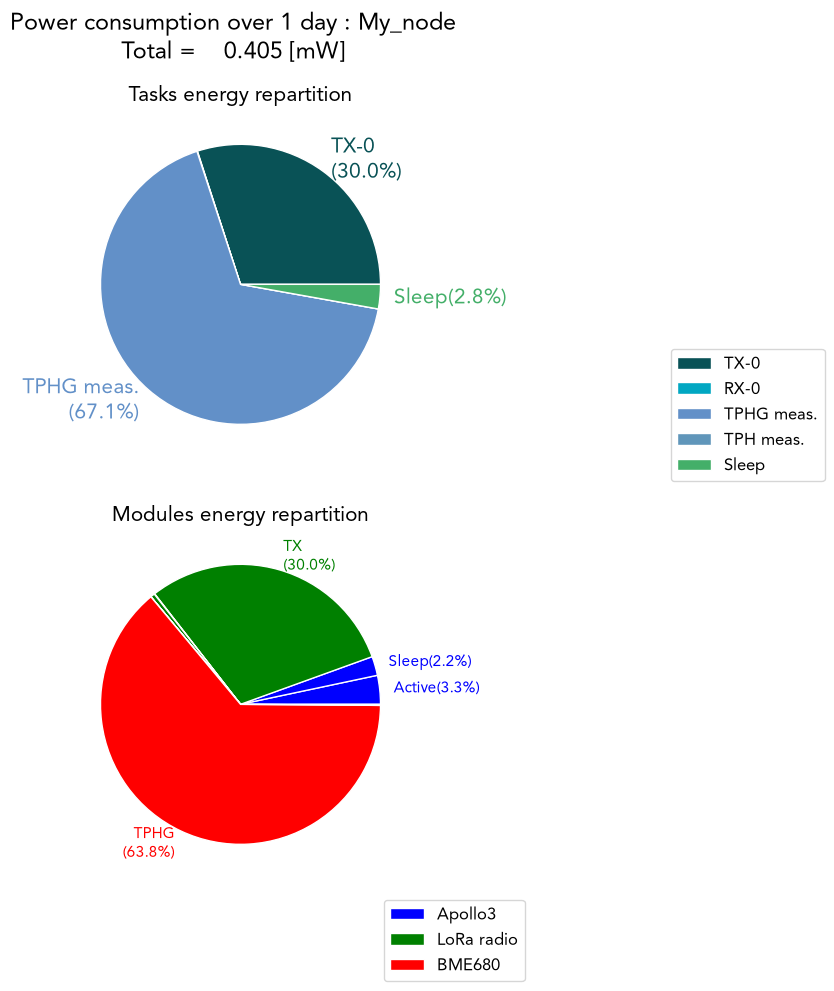

In [ ]:
this_task_tx0.set_distance( d= 1000)
this_node.compute()
this_node.print_tasks()
this_node.print_components()
this_node.plot_power()

In [ ]:

AA_series = 3
AA_footprint = 0.165
AA_cost      = 0.25 
Batt_footprint = AA_series*AA_footprint
Batt_cost      = AA_series*AA_cost


Connectivity = radio_component_3V3
Processing   = apollo_component_3V3
Sensing      = bme_component_3V3
Power_supply = this_LDO

In [ ]:
footprintStructure = FootprintStructure(("GWP", "Money"), units=("$kgCO_2 eq.$", "EUR"))
this_hw.set_footprint_structure(footprintStructure)

In [ ]:
Casing                  .set_factors(footprintStructure.vector(GWP=(0.3932,   0.709,   1.3259), Money=10))
Connectivity            .set_factors(footprintStructure.vector(GWP=(0.2262,   0.517,   0.5817), Money=5.3))   # SX1276 : 5.3
EoL                     .set_factors(footprintStructure.vector(GWP=(0.0388,   0.0812,  0.1201), Money=0))
Others                  .set_factors(footprintStructure.vector(GWP=(0.0546,   0.0938,  0.1394), Money=1.42)) ##MLCC : 0.05*15 + XTAL32MHz: 0.5 + R: 0.002*15 + D : 0.07*2 
PCB                     .set_factors(footprintStructure.vector(GWP=(0.9403,   1.17,    1.5696), Money=1.17))
Power_supply            .set_factors(footprintStructure.vector(GWP=(0.0446,   0.132,   0.1751), Money=0.228))
Processing              .set_factors(footprintStructure.vector(GWP=(0.366,    0.366,   0.4537), Money=3.65))   # Apollo3: 3.65this_Batt= Battery(name = "Node Batt.", category = "Battery", v = 3.3, capacity_mAh = 2800, i = 0, selfdischarge_p_year = 5,
Sensing                 .set_factors(footprintStructure.vector(GWP=(0.0539,   0.0539,  0.5561), Money=6.94)) 
UI                      .set_factors(footprintStructure.vector(GWP=(0.0017,   0.0306, 0.1155), Money=0.54))
this_Batt               .set_factors(footprintStructure.vector(GWP=(Batt_footprint  ,Batt_footprint,Batt_footprint), Money=Batt_cost))


Category      GWP [$kgCO_2 eq.$]       Money [EUR]
------------  -----------------------  -----------
Casing        [0.393, 0.709, 1.33]     10         
Connectivity  [0.226, 0.517, 0.582]    5.3        
EoL           [0.0388, 0.0812, 0.12]   0          
Memory        0                        0          
Others        [0.0546, 0.0938, 0.139]  1.42       
PCB           [0.94, 1.17, 1.57]       1.17       
Power_supply  [0.0446, 0.132, 0.175]   0.228      
Processing    [0.366, 0.366, 0.454]    3.65       
Sensing       [0.0539, 0.0539, 0.556]  6.94       
UI            [0.0017, 0.0306, 0.116]  0.54       
Battery       0.495                    0.75       
------------  -----------------------  -----------
Total         [2.61, 3.65, 5.53]       30         


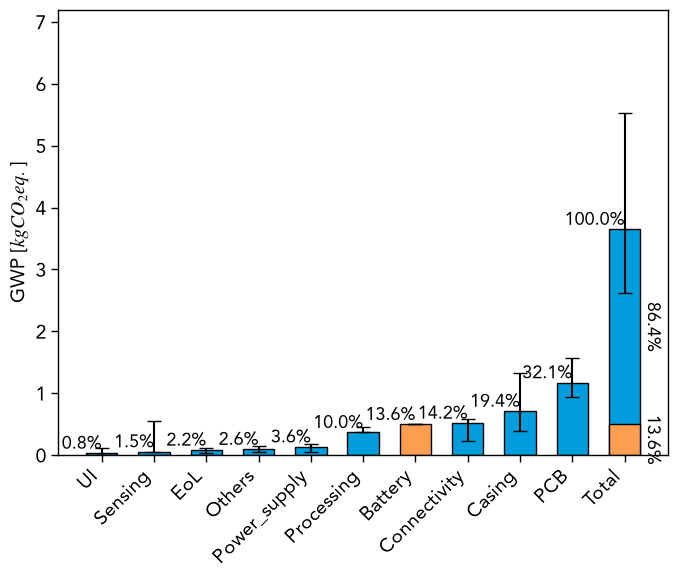

In [ ]:

this_hw.compute_footprint()
this_hw.report_footprint()
this_hw.plot_footprint(label="GWP")

In [53]:

#importlib.reload(IoT_node_models)
#from IoT_node_models import *

In [54]:
Nyears=30

placementNnodes   = 100
decomNnodes       = 100
replacementNnodes = 10

#placementTransport      = Transport(n_node=placementNnodes  , km_fixed=80, km_p_node=1, footprint_p_km=0.350, label="GWP")
#decomTransport          = Transport(n_node=decomNnodes      , km_fixed=80, km_p_node=1, footprint_p_km=0.350, label="GWP")
#replacementTransport    = Transport(n_node=replacementNnodes, km_fixed=80, km_p_node=1, footprint_p_km=0.350, label="GWP")

placementTransport      = Dum_Transport(n_node=placementNnodes  , km_fixed=40, km_p_node=5, footprint_p_km=0.350, label="GWP")
decomTransport          = Dum_Transport(n_node=decomNnodes      , km_fixed=40, km_p_node=5, footprint_p_km=0.350, label="GWP")
replacementTransport    = Dum_Transport(n_node=replacementNnodes, km_fixed=40, km_p_node=5, footprint_p_km=0.350, label="GWP")

deploymentStart = DeploymentStrategy_wTransport( Nyears=Nyears, replacementCategories=None,#("Battery",),
                  transport_placement     =placementTransport, 
                  transport_replacement   =replacementTransport, 
                  transport_decom         =decomTransport,
                  smooth_replacement_footprint = True)

this_node.set_deployment_strategy(deploymentStart)
this_node.compute()

d:\Pol\Documents\Research\Git_Iot_node_modeling\IoT_node_models\Node_description\Node_description.py:328: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


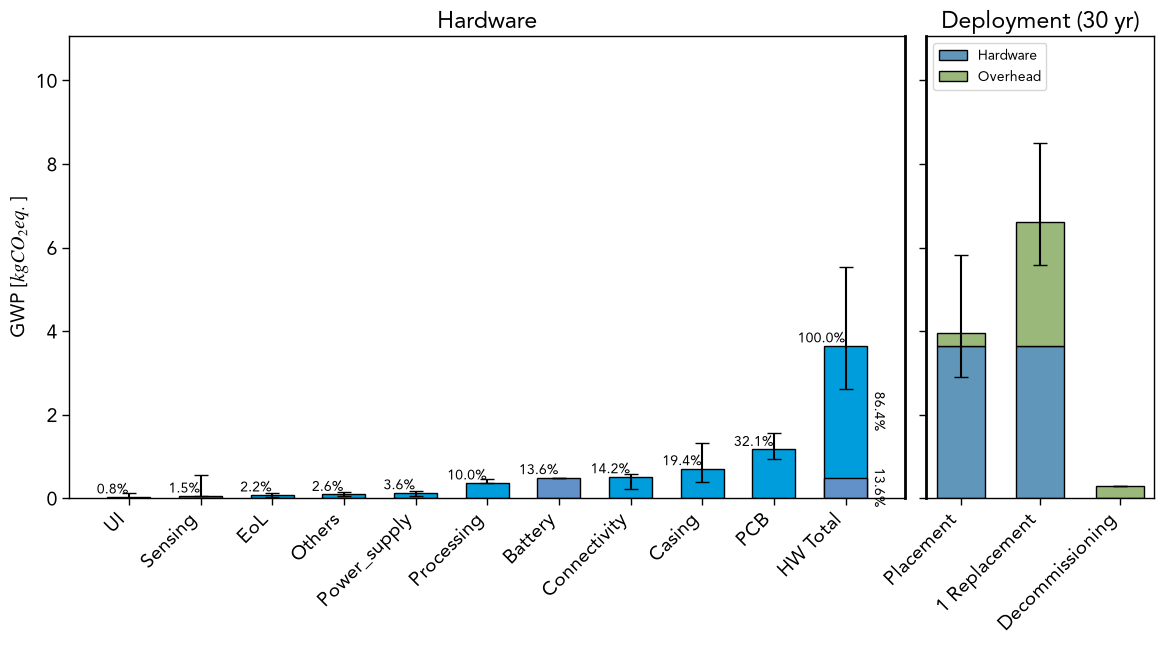

In [55]:
this_node.plot_footprint(label="GWP",cumulated_replacement=False)

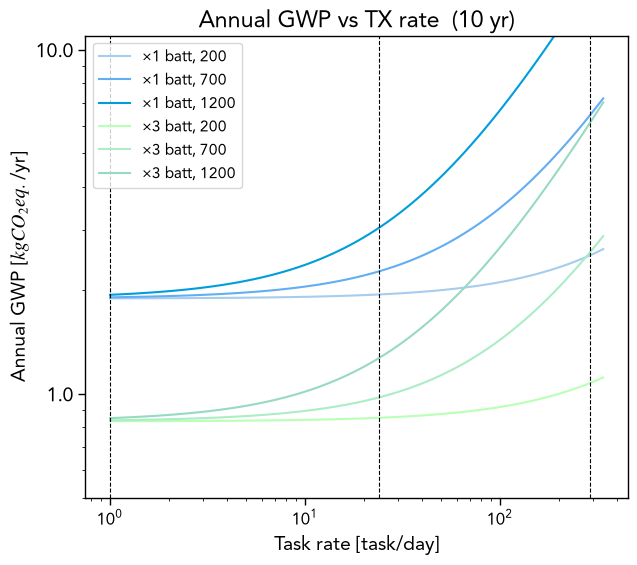

In [56]:
this_node.deployment_strategy.Nyears = 10

colorList = [listBlue, listGreen]

fig, ax = sweep_task_rate(this_node, this_task_tx0,
    label="GWP", rate_min=1, rate_max=24*12+50, n_rate=100, sweep_log=True,
    nAA=[1, 3],
    param_values=[200, 700, 1200], paramType="dnode", ylim = (0.5,11),colorList=colorList)

this_node.deployment_strategy.Nyears = Nyears

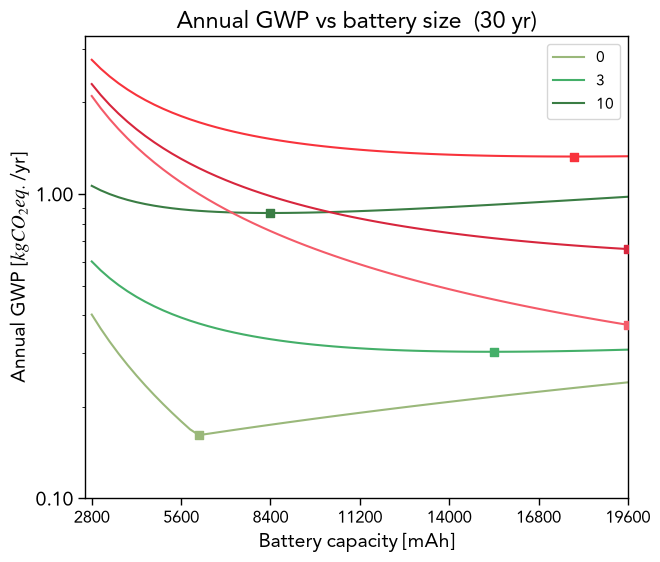

In [62]:

this_node.profile.change_task_rate(this_task_tx0,24)
this_task_tx0.set_distance(d= 700)


this_node.profile.change_task_rate(task_TPHG_3V3,0)
this_node.profile.change_task_rate(task_TPH_3V3 ,24*12)

# sweep battery size — three self-discharge values
fig, ax = sweep_ebatt(this_node,
    label="GWP", nAAmin=1, nAAmax=7, nAA_step=0.1, colorList=listGreen[3:],
    param_values=[0, 3, 10], paramType="rsd", ylim =(0.1,  3.3), xlim = (2600,19600))


this_node.profile.change_task_rate(task_TPHG_3V3,24*12)
this_node.profile.change_task_rate(task_TPH_3V3 ,0)

# sweep battery size — three self-discharge values
fig, ax = sweep_ebatt(this_node,
    label="GWP", nAAmin=1, nAAmax=7, nAA_step=0.1, colorList=listRed,
    param_values=[0, 3, 10], paramType="rsd", figAppend = [fig, ax] )

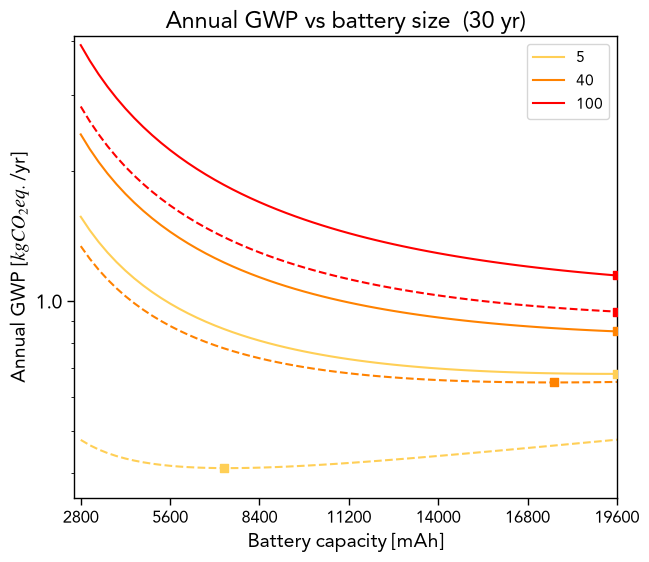

In [63]:
colorList = [orangeDict["Maize"], orangeDict["Orange2"] , orangeDict["Red"]]

fig, ax = sweep_ebatt(this_node,
    label="GWP", nAAmin=1, nAAmax=7, nAA_step=0.1,
    transport_refs=[placementTransport, decomTransport, replacementTransport],
    replacementCategories=None, colorList=colorList, linestyle ='-',
    param_values=[5,40,100], paramType="dtrans", ylim =(0.35, 4.1) , xlim = (2600,19600))

fig, ax = sweep_ebatt(this_node,
    label="GWP", nAAmin=1, nAAmax=7, nAA_step=0.1,
    transport_refs=[placementTransport, decomTransport, replacementTransport],
    replacementCategories=("Battery",), colorList=colorList, linestyle ='--',
    param_values=[5,40,100], paramType="dtrans",  figAppend=[fig,ax] )

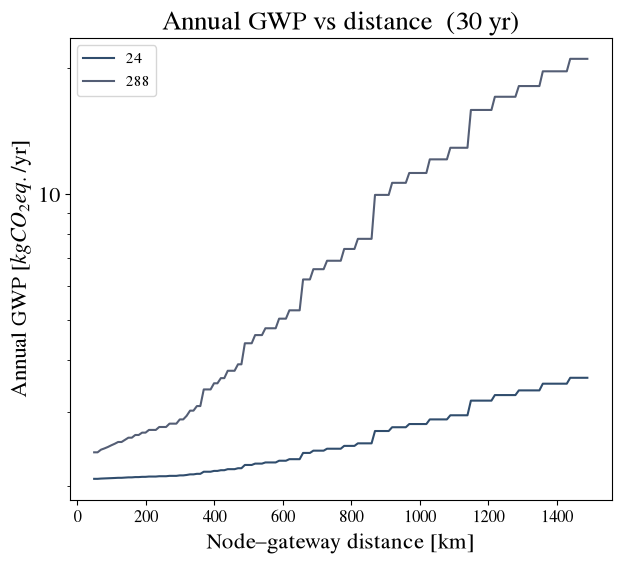

In [ ]:

# sweep distance — two TX rates
fig, ax = sweep_dnode(this_node, this_task_tx0,
    label="GWP", dmin=50, dmax=1500, d_step=10,
    param_values=[24, 24*12], paramType="task_rate")